# **1.Import Libraries**

In [1]:
from google.colab import drive

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import joblib
import os


# **2.Import Data from Google Drive**

In [2]:
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/sms+spam+collection/SMSSpamCollection'

df = pd.read_csv(
    file_path,
    sep='\t',
    header=None,
    names=['label', 'message']
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **3.Understand Data**

In [3]:
print("Dataset Head:")
display(df.head())

print("\nDataset Shape:")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\nDataset Info:")
df.info()

print("\nDataset Description:")
display(df.describe(include='all'))

print("\nDataset Missing Values:")
print(df.isnull().sum())

print("\nDataset Duplicate Values:")
print(df.duplicated().sum())

label_distribution = pd.DataFrame({
    'Count': df['label'].value_counts(),
    'Percentage': df['label'].value_counts(normalize=True) * 100
})

print("\nLabel Distribution:")
display(label_distribution.round(2))

Dataset Head:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Dataset Shape:
Rows: 5572, Columns: 2

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Dataset Description:


,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30



Dataset Missing Values:
label      0
message    0
dtype: int64

Dataset Duplicate Values:
403

Label Distribution:


,Count,Percentage
label,,
ham,4825,86.59
spam,747,13.41


# **4.Data Cleaning**

In [4]:
df['label'] = df['label'].str.strip().str.lower()
df['message'] = df['message'].str.strip()

In [5]:
print("Duplicates Before Cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates After Cleaning:", df.duplicated().sum())
print("Dataset Shape After Cleaning:", df.shape)

Duplicates Before Cleaning: 414
Duplicates After Cleaning: 0
Dataset Shape After Cleaning: (5158, 2)


In [6]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

words_to_keep = {
    'not', 'no', 'nor',
    'what', 'where', 'how', 'you', 'doing'
}

stop_words = stop_words - words_to_keep

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
def clean_text(text):

    text = text.lower()

    # Handle common negative contractions
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"n't\b", " not", text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation
    text = re.sub(r'[^\w\s]', ' ', text)

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return ' '.join(words)

In [8]:
df['cleaned_message'] = df['message'].apply(clean_text)

In [9]:
print("\nOriginal and Cleaned Messages:")
display(df[['message', 'cleaned_message']].head(10))

print("\nDataset Shape After Cleaning:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nEmpty Cleaned Messages:")
print((df['cleaned_message'].str.strip() == '').sum())


Original and Cleaned Messages:


,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah not think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling week no word back like fun...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aids pa...
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer you selected re...
9,Had your mobile 11 months or more? U R entitle...,mobile months u r entitled update latest colou...



Dataset Shape After Cleaning:
(5158, 3)

Missing Values:
label              0
message            0
cleaned_message    0
dtype: int64

Duplicate Rows:
0

Empty Cleaned Messages:
3


In [10]:
empty_messages = df[
    df['cleaned_message'].str.strip() == ''
]

display(empty_messages[['label', 'message', 'cleaned_message']])

,label,message,cleaned_message
1612,ham,645,
3376,ham,:),
4824,ham,:-) :-),


In [11]:
# Remove rows with empty cleaned messages
df = df[df['cleaned_message'].str.strip() != ''].copy()

print("Dataset Shape After Removing Empty Messages:", df.shape)
print("Empty Cleaned Messages:", (df['cleaned_message'].str.strip() == '').sum())

Dataset Shape After Removing Empty Messages: (5155, 3)
Empty Cleaned Messages: 0


# **5.Feature Engineering**

In [12]:
df['message_length'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()

In [13]:
print("Dataset After Feature Engineering:")
display(df.head())

Dataset After Feature Engineering:


,label,message,cleaned_message,message_length,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...,111,20
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...,155,28
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah not think goes usf lives around though,61,13


In [14]:
print("\nAverage Features by Label:")

display(
    df.groupby('label')[['message_length', 'word_count']]
    .mean()
    .round(2)
)


Average Features by Label:


,message_length,word_count
label,,
ham,70.91,14.25
spam,137.41,23.70


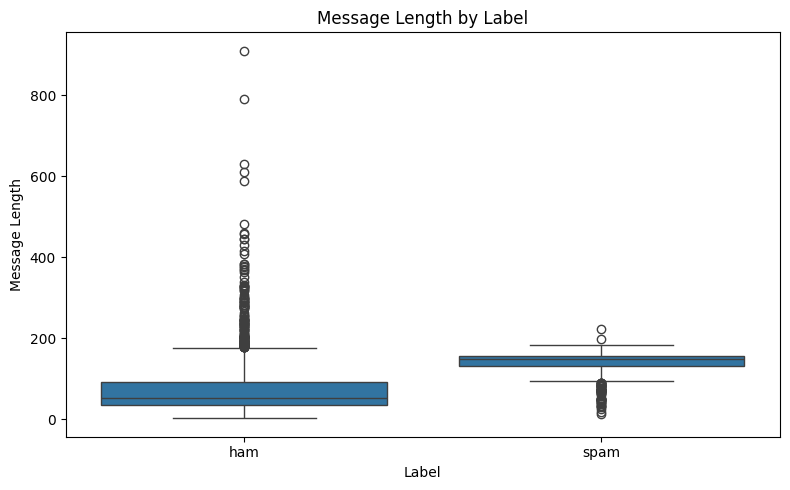

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='label',
    y='message_length'
)

plt.title('Message Length by Label')
plt.xlabel('Label')
plt.ylabel('Message Length')
plt.tight_layout()
plt.show()

# **6.Data Splitting**

In [16]:
X = df['cleaned_message']
y = df['label']

In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [18]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [19]:
print("Training Set Shape:", X_train.shape)
print("Validation Set Shape:", X_val.shape)
print("Testing Set Shape:", X_test.shape)

Training Set Shape: (3608,)
Validation Set Shape: (773,)
Testing Set Shape: (774,)


In [20]:
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} Label Distribution:")
    display(
        labels.value_counts()
        .to_frame('Count')
        .assign(Percentage=lambda x: (x['Count'] / len(labels) * 100).round(2))
    )


Training Label Distribution:


,Count,Percentage
label,,
ham,3159,87.56
spam,449,12.44



Validation Label Distribution:


,Count,Percentage
label,,
ham,677,87.58
spam,96,12.42



Testing Label Distribution:


,Count,Percentage
label,,
ham,677,87.47
spam,97,12.53


# **7.Feature Extraction using TF-IDF**

In [21]:
tfidf = TfidfVectorizer()

In [22]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

In [23]:
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (3608, 6222)
Validation TF-IDF Shape: (773, 6222)
Testing TF-IDF Shape: (774, 6222)


In [24]:
print("\nVocabulary Size:", len(tfidf.vocabulary_))


Vocabulary Size: 6222


# **8.Model Building & Training**

***Experiment 1: Logistic Regression***

In [25]:
#Model Training
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [26]:
#Predictions
y_pred_lr = lr_model.predict(X_val_tfidf)

In [27]:
#Evaluation
print("Logistic Regression - Validation Results")

print("\nAccuracy:", accuracy_score(y_val, y_pred_lr))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_lr,
    labels=['ham', 'spam'],
    target_names=['ham', 'spam'],
    zero_division=0
))

Logistic Regression - Validation Results

Accuracy: 0.96248382923674

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       677
        spam       0.99      0.71      0.82        96

    accuracy                           0.96       773
   macro avg       0.97      0.85      0.90       773
weighted avg       0.96      0.96      0.96       773



Confusion Matrix:
[[676   1]
 [ 28  68]]


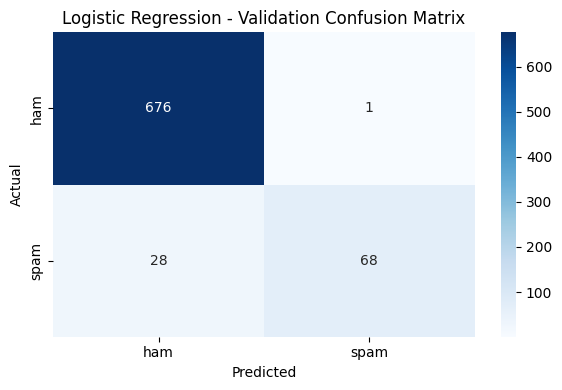

In [28]:
#Confusion Matrix

cm_lr = confusion_matrix(
    y_val,
    y_pred_lr,
    labels=['ham', 'spam']
)

print("Confusion Matrix:")
print(cm_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Validation Confusion Matrix')

plt.tight_layout()
plt.show()

***Experiment 2: Linear SVM***

In [29]:
#Model Training

svm_model = LinearSVC(
    max_iter=2000,
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

print("Linear SVM Training Completed!")

Linear SVM Training Completed!


In [30]:
#Predictions

y_pred_svm = svm_model.predict(X_val_tfidf)

In [31]:
#Evaluation
print("Linear SVM - Validation Results")

print("\nAccuracy:", accuracy_score(y_val, y_pred_svm))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_pred_svm,
    labels=['ham', 'spam'],
    target_names=['ham', 'spam'],
    zero_division=0
))

Linear SVM - Validation Results

Accuracy: 0.9805950840879689

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       677
        spam       0.98      0.86      0.92        96

    accuracy                           0.98       773
   macro avg       0.98      0.93      0.95       773
weighted avg       0.98      0.98      0.98       773



Confusion Matrix:
[[675   2]
 [ 13  83]]


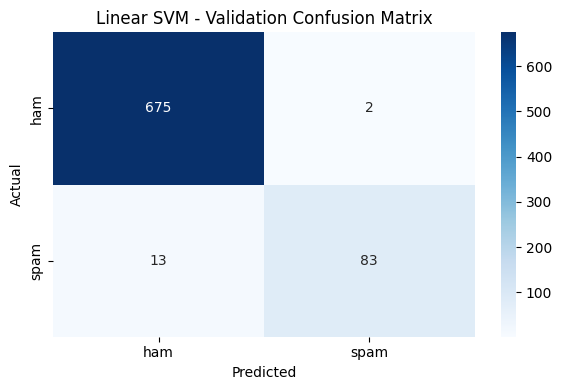

In [32]:
#Confusion Matrix
cm_svm = confusion_matrix(
    y_val,
    y_pred_svm,
    labels=['ham', 'spam']
)

print("Confusion Matrix:")
print(cm_svm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Linear SVM - Validation Confusion Matrix')

plt.tight_layout()
plt.show()

# **9.Hyperparameter Tuning**

***9.1 Logistic Regression Tuning***

In [33]:
C_values = [0.01, 0.1, 1, 10, 100]

lr_results = []

for c in C_values:

    model = LogisticRegression(
        C=c,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    spam_f1 = f1_score(
        y_val,
        y_val_pred,
        pos_label='spam'
    )

    lr_results.append({
        'C': c,
        'Spam F1-score': spam_f1
    })

In [34]:
lr_results_df = pd.DataFrame(lr_results)

print("Logistic Regression Tuning Results:")
display(lr_results_df.round(4))


# Select Best Hyperparameter
best_lr_C = lr_results_df.loc[
    lr_results_df['Spam F1-score'].idxmax(),
    'C'
]

print("Best Logistic Regression C:", best_lr_C)

Logistic Regression Tuning Results:


,C,Spam F1-score
0,0.01,0.0000
1,0.10,0.0000
2,1.00,0.8242
3,10.00,0.8927
4,100.00,0.9061


Best Logistic Regression C: 100.0


***9.2 Linear SVM Tuning***

In [35]:
svm_results = []

for c in C_values:

    model = LinearSVC(
      C=c,
      max_iter=2000,
      random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    spam_f1 = f1_score(
        y_val,
        y_val_pred,
        pos_label='spam'
    )

    svm_results.append({
        'C': c,
        'Spam F1-score': spam_f1
    })

In [36]:
svm_results_df = pd.DataFrame(svm_results)

print("Linear SVM Tuning Results:")
display(svm_results_df.round(4))


# Select Best Hyperparameter
best_svm_C = svm_results_df.loc[
    svm_results_df['Spam F1-score'].idxmax(),
    'C'
]

print("Best Linear SVM C:", best_svm_C)

Linear SVM Tuning Results:


,C,Spam F1-score
0,0.01,0.0000
1,0.10,0.8471
2,1.00,0.9171
3,10.00,0.9290
4,100.00,0.9297


Best Linear SVM C: 100.0


# **10.Train Final Models**

*10.1 Final Logistic Regression*

In [37]:
final_lr_model = LogisticRegression(
    C=best_lr_C,
    max_iter=1000,
    random_state=42
)

final_lr_model.fit(X_train_tfidf, y_train)

print("Final Logistic Regression Training Completed!")
print("Selected C:", best_lr_C)

Final Logistic Regression Training Completed!
Selected C: 100.0


10.2 Final Linear SVM

In [38]:
final_svm_model = LinearSVC(
    C=best_svm_C,
    max_iter=2000,
    random_state=42
)

final_svm_model.fit(X_train_tfidf, y_train)

print("Final Linear SVM Training Completed!")
print("Selected C:", best_svm_C)

Final Linear SVM Training Completed!
Selected C: 100.0


# **11. Model Persistence**

In [39]:
# Create a folder to save the trained models
models_path = '/content/drive/MyDrive/SMS_Spam_Models'
os.makedirs(models_path, exist_ok=True)

# Save TF-IDF Vectorizer
joblib.dump(tfidf, os.path.join(models_path, 'tfidf_vectorizer.pkl'))

# Save Logistic Regression Model
joblib.dump(final_lr_model, os.path.join(models_path, 'logistic_regression_model.pkl'))

# Save Linear SVM Model
joblib.dump(final_svm_model, os.path.join(models_path, 'linear_svm_model.pkl'))

print("All models and vectorizer saved successfully!")

All models and vectorizer saved successfully!


In [40]:
# Load TF-IDF Vectorizer
loaded_tfidf = joblib.load(
    os.path.join(models_path, 'tfidf_vectorizer.pkl')
)

# Load Logistic Regression Model
loaded_lr_model = joblib.load(
    os.path.join(models_path, 'logistic_regression_model.pkl')
)

# Load Linear SVM Model
loaded_svm_model = joblib.load(
    os.path.join(models_path, 'linear_svm_model.pkl')
)

print("All models and vectorizer loaded successfully!")

All models and vectorizer loaded successfully!


In [41]:
# Test with a new SMS message
new_message = "Congratulations! You have won a free prize. Call now to claim your reward."

# Apply the same text cleaning
cleaned_message = clean_text(new_message)

# Transform using the loaded TF-IDF vectorizer
message_vector = loaded_tfidf.transform([cleaned_message])

# Predict using the loaded models
lr_prediction = loaded_lr_model.predict(message_vector)[0]
svm_prediction = loaded_svm_model.predict(message_vector)[0]

print("Original Message:", new_message)
print("Cleaned Message:", cleaned_message)
print("Logistic Regression Prediction:", lr_prediction)
print("Linear SVM Prediction:", svm_prediction)

Original Message: Congratulations! You have won a free prize. Call now to claim your reward.
Cleaned Message: congratulations you free prize call claim reward
Logistic Regression Prediction: spam
Linear SVM Prediction: spam


# **12.Final Predictions**

In [42]:
y_test_pred_lr = final_lr_model.predict(X_test_tfidf)

y_test_pred_svm = final_svm_model.predict(X_test_tfidf)

print("Final Predictions Completed!")

Final Predictions Completed!


# **13.Final Model Evaluation**

*13.1 Logistic Regression*

In [43]:
print("Logistic Regression - Final Test Results")

print("\nAccuracy:")
print(accuracy_score(y_test, y_test_pred_lr))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred_lr,
    labels=['ham', 'spam'],
    target_names=['ham', 'spam'],
    zero_division=0
))

Logistic Regression - Final Test Results

Accuracy:
0.9767441860465116

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       677
        spam       0.99      0.82      0.90        97

    accuracy                           0.98       774
   macro avg       0.98      0.91      0.94       774
weighted avg       0.98      0.98      0.98       774



*13.2 Linear SVM*

In [44]:
print("Linear SVM - Final Test Results")

print("\nAccuracy:")
print(accuracy_score(y_test, y_test_pred_svm))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred_svm,
    labels=['ham', 'spam'],
    target_names=['ham', 'spam'],
    zero_division=0
))

Linear SVM - Final Test Results

Accuracy:
0.9806201550387597

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       677
        spam       0.98      0.87      0.92        97

    accuracy                           0.98       774
   macro avg       0.98      0.93      0.95       774
weighted avg       0.98      0.98      0.98       774



# **14.Confusion Matrices**

In [45]:
cm_lr = confusion_matrix(
    y_test,
    y_test_pred_lr,
    labels=['ham', 'spam']
)

cm_svm = confusion_matrix(
    y_test,
    y_test_pred_svm,
    labels=['ham', 'spam']
)

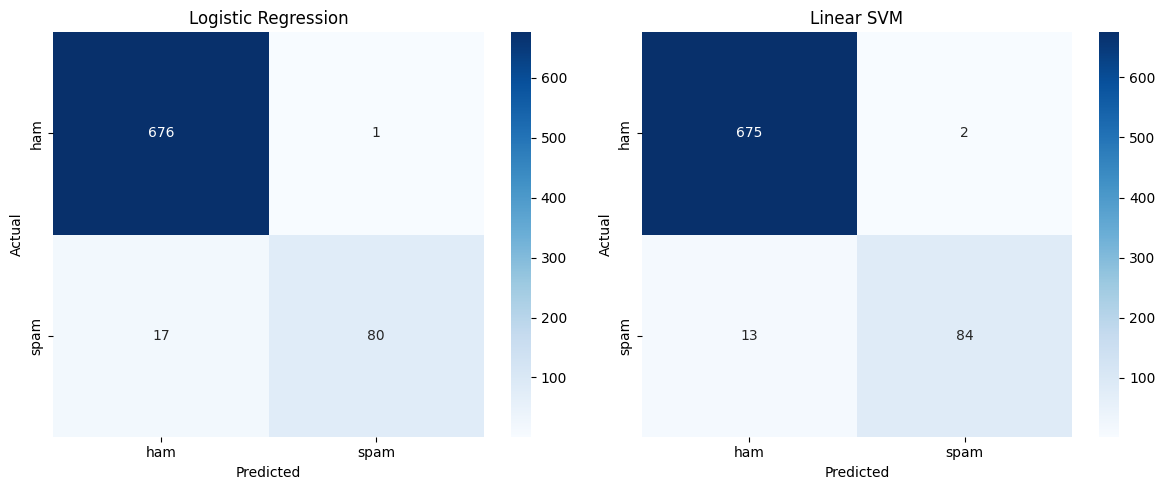

In [46]:
# Create Side-by-Side Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


# Logistic Regression
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam'],
    ax=axes[0]
)

axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')


# Linear SVM
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam'],
    ax=axes[1]
)

axes[1].set_title('Linear SVM')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')


plt.tight_layout()
plt.show()

# **15.Final Model Comparison**

In [47]:
# 14. Final Model Comparison

# Generate Classification Reports as Dictionaries
lr_report = classification_report(
    y_test,
    y_test_pred_lr,
    labels=['ham', 'spam'],
    output_dict=True,
    zero_division=0
)

svm_report = classification_report(
    y_test,
    y_test_pred_svm,
    labels=['ham', 'spam'],
    output_dict=True,
    zero_division=0
)


# Create Comparison Table
comparison_df = pd.DataFrame({
    'Metric': [
        'Best C',
        'Accuracy',
        'Spam Precision',
        'Spam Recall',
        'Spam F1-score'
    ],
    'Logistic Regression': [
        best_lr_C,
        accuracy_score(y_test, y_test_pred_lr),
        lr_report['spam']['precision'],
        lr_report['spam']['recall'],
        lr_report['spam']['f1-score']
    ],
    'Linear SVM': [
        best_svm_C,
        accuracy_score(y_test, y_test_pred_svm),
        svm_report['spam']['precision'],
        svm_report['spam']['recall'],
        svm_report['spam']['f1-score']
    ]
})

print("Final Model Comparison:")
display(comparison_df.round(4))

Final Model Comparison:


,Metric,Logistic Regression,Linear SVM
0,Best C,100.0000,100.0000
1,Accuracy,0.9767,0.9806
2,Spam Precision,0.9877,0.9767
3,Spam Recall,0.8247,0.8660
4,Spam F1-score,0.8989,0.9180
